# **Project 1: eCommerce Sales Performance & Profitability Analysis (2014–2017**)
**Author:** Anshul Kumar Singh | **Program:** Data Analyst Trainee Program  
**Tech Stack:** Python (Pandas, NumPy, Matplotlib, Seaborn) • SQL (SQLite) • Interactive Plotly.js Dashboard  
**Dataset:** Retail Superstore Sales Dataset (`9,993` cleaned transactions | `5,009` unique orders | `793` customers)

---

### 📌 Project Objective
End-to-end data cleaning, SQL aggregation, exploratory data analysis (EDA), and interactive dashboard modeling to uncover regional revenue drivers, product category profitability, customer spending segments, and discount margin erosion.

# **Step 1: Data Loading & Setup**

In [2]:
import sqlite3
import zipfile
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display
from google.colab import files

# Upload Sample - Superstore.csv if not already present
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Load raw data
raw_df = pd.read_csv(filename, encoding='windows-1252')
print(f"Raw Dataset Loaded successfully! Shape: {raw_df.shape}")

Saving Sample - Superstore.csv to Sample - Superstore (1).csv
Raw Dataset Loaded successfully! Shape: (9994, 21)


# **Step 2: Data Cleaning & Quality Audit**

In this step, we clean the raw transactional data by removing duplicate records (ignoring Row ID), standardizing date-time objects, fixing postal code formatting, and running a programmatic data quality audit to ensure zero null values and proper chronological alignment.

In [3]:
# 1. Remove duplicate order lines (ignoring Row ID) & standardize text
cols_without_rowid = [c for c in raw_df.columns if c != 'Row ID']
duplicate_count = raw_df.duplicated(subset=cols_without_rowid).sum()

df = raw_df.drop_duplicates(subset=cols_without_rowid).reset_index(drop=True)
df['Product Name'] = df['Product Name'].str.strip()

# 2. Standardize date types & postal codes
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Postal Code'] = df['Postal Code'].astype(str).str.zfill(5)

# 3. Feature Engineering for Analysis
df['Order Year'] = df['Order Date'].dt.year
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Profit Margin %'] = ((df['Profit'] / df['Sales']) * 100).round(2)
df['Is_Loss'] = df['Profit'] < 0
df['Discount_Band'] = pd.cut(
    df['Discount'],
    bins=[-0.001, 0, 0.20, 0.29, 0.45, 1.0],
    labels=['0% (No Discount)', '1–20% (Safe)', '21–29% (Caution)', '30–45% (Loss Zone)', 'Over 45% (Severe Loss)']
)

# 4. Programmatic Data Quality Audit Table
audit_df = pd.DataFrame([
    ["Total Rows & Columns", "PASS", f"{df.shape[0]:,} x {df.shape[1]}", "Cleaned schema ready"],
    ["Missing Values", "PASS", f"{df.isna().sum().sum()}", "Zero nulls across all columns"],
    ["Duplicate Transactions Removed", "CLEANED", f"{duplicate_count} row removed", "Exact duplicate items dropped"],
    ["Chronological Shipping Check (Ship < Order)", "PASS", f"{(df['Shipping Days'] < 0).sum()}", "All shipments >= 0 days"]
], columns=["Audit Check", "Status", "Observed", "Engineering Action"])

display(audit_df.style.hide(axis="index"))

# Save cleaned CSV for BI reporting
df.to_csv('superstore_cleaned.csv', index=False)
print(f"Cleaned dataset saved as 'superstore_cleaned.csv' ({len(df):,} rows)")

Audit Check,Status,Observed,Engineering Action
Total Rows & Columns,PASS,"9,993 x 27",Cleaned schema ready
Missing Values,PASS,0,Zero nulls across all columns
Duplicate Transactions Removed,CLEANED,1 row removed,Exact duplicate items dropped
Chronological Shipping Check (Ship < Order),PASS,0,All shipments >= 0 days


Cleaned dataset saved as 'superstore_cleaned.csv' (9,993 rows)


# **🗄️ Step 3: SQL Data Aggregation**
We load our cleaned DataFrame into an in-memory SQLite database to compute Total Orders, Total Sales, Average Line Sales, Total Profit, and Net Margins grouped across Regions, Product Categories, and Time Periods (Years).

In [4]:
conn = sqlite3.connect(':memory:')
df.to_sql('sales_data', conn, index=False)

sql_queries = {
    "1. Aggregation by Region": """
        SELECT Region,
               COUNT(DISTINCT "Order ID") AS Total_Orders,
               ROUND(SUM(Sales), 2) AS Total_Sales,
               ROUND(AVG(Sales), 2) AS Avg_Sales,
               ROUND(SUM(Profit), 2) AS Total_Profit,
               ROUND((SUM(Profit) / SUM(Sales)) * 100, 2) AS Margin_Pct
        FROM sales_data
        GROUP BY Region
        ORDER BY Total_Sales DESC;
    """,
    "2. Aggregation by Product Category": """
        SELECT Category,
               COUNT(DISTINCT "Order ID") AS Total_Orders,
               ROUND(SUM(Sales), 2) AS Total_Sales,
               ROUND(AVG(Sales), 2) AS Avg_Sales,
               ROUND(SUM(Profit), 2) AS Total_Profit,
               ROUND((SUM(Profit) / SUM(Sales)) * 100, 2) AS Margin_Pct
        FROM sales_data
        GROUP BY Category
        ORDER BY Total_Sales DESC;
    """,
    "3. Aggregation by Time Period (Year)": """
        SELECT "Order Year" AS Year,
               COUNT(DISTINCT "Order ID") AS Total_Orders,
               ROUND(SUM(Sales), 2) AS Total_Sales,
               ROUND(AVG(Sales), 2) AS Avg_Sales,
               ROUND(SUM(Profit), 2) AS Total_Profit,
               ROUND((SUM(Profit) / SUM(Sales)) * 100, 2) AS Margin_Pct
        FROM sales_data
        GROUP BY "Order Year"
        ORDER BY Year;
    """
}

for title, query in sql_queries.items():
    print(f"\n--- {title} ---")
    display(pd.read_sql(query, conn))


--- 1. Aggregation by Region ---


,Region,Total_Orders,Total_Sales,Avg_Sales,Total_Profit,Margin_Pct
0,West,1611,725457.82,226.49,108418.45,14.94
1,East,1401,678499.87,238.32,91534.84,13.49
2,Central,1175,501239.89,215.77,39706.36,7.92
3,South,822,391721.91,241.80,46749.43,11.93



--- 2. Aggregation by Product Category ---


,Category,Total_Orders,Total_Sales,Avg_Sales,Total_Profit,Margin_Pct
0,Technology,1544,836154.03,452.71,145454.95,17.40
1,Furniture,1764,741718.42,349.87,18463.33,2.49
2,Office Supplies,3742,719047.03,119.32,122490.80,17.04



--- 3. Aggregation by Time Period (Year) ---


,Year,Total_Orders,Total_Sales,Avg_Sales,Total_Profit,Margin_Pct
0,2014,969,483966.13,242.95,49556.03,10.24
1,2015,1038,470532.51,223.85,61618.60,13.10
2,2016,1315,609205.60,235.49,81795.17,13.43
3,2017,1687,733215.26,221.38,93439.27,12.74


# **📈 Step 4: Exploratory Data Analysis & Visualizations**
Generating high-resolution plots to fulfill project requirements:
1. Monthly Sales Trends (Line Chart)
2. Sub-Category Sales & Profit Distribution (Bar Chart)
3. Top 10 Performing Products (Table & CSV)
4. Customer Segmentation by Spend vs. Orders (Scatter Plot)

In [5]:
sns.set_style("whitegrid")

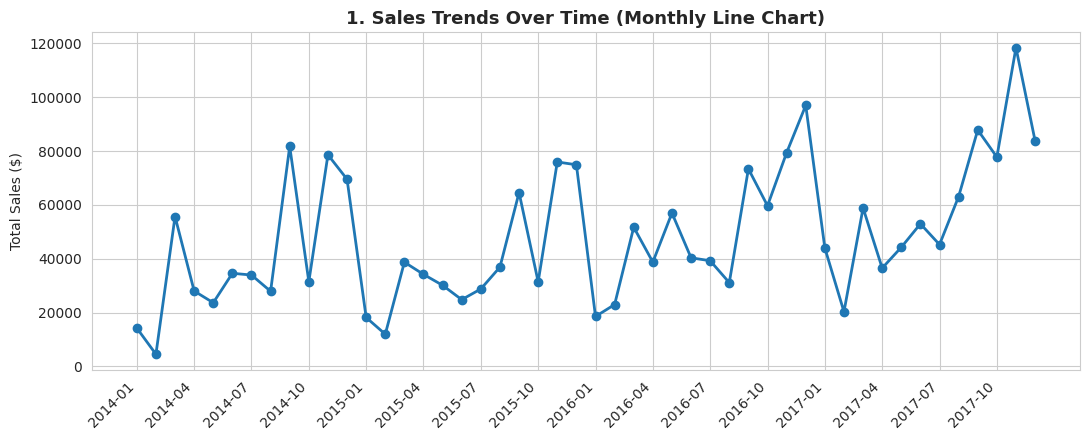

In [6]:
# Visual 1: Sales Trends Over Time
monthly = df.groupby('Year-Month')['Sales'].sum().reset_index()
plt.figure(figsize=(11, 4.5))
plt.plot(monthly['Year-Month'], monthly['Sales'], color='#1f77b4', marker='o', linewidth=2)
plt.xticks(monthly['Year-Month'][::3], rotation=45, ha='right')
plt.title('1. Sales Trends Over Time (Monthly Line Chart)', fontsize=13, fontweight='bold')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.savefig('1_sales_trends_line_chart.png', dpi=300)
plt.show()

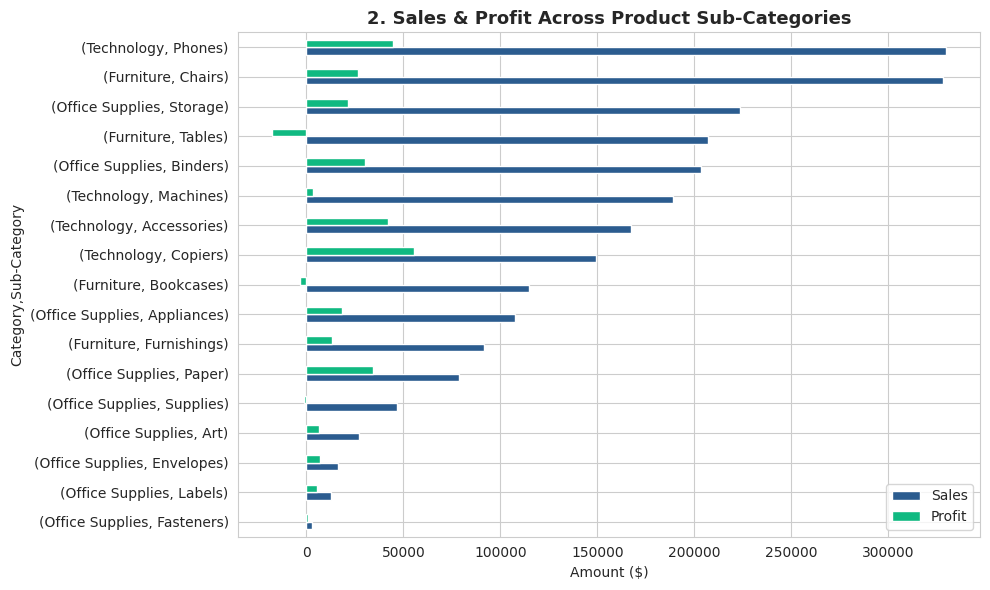

In [7]:
# Visual 2: Sales Distribution Across Sub-Categories
cat_sales = df.groupby(['Category', 'Sub-Category'])[['Sales', 'Profit']].sum().sort_values('Sales', ascending=True)
cat_sales.plot(kind='barh', figsize=(10, 6), color=['#2b5c8f', '#10b981'])
plt.title('2. Sales & Profit Across Product Sub-Categories', fontsize=13, fontweight='bold')
plt.xlabel('Amount ($)')
plt.tight_layout()
plt.savefig('2_category_distribution_bar_chart.png', dpi=300)
plt.show()

In [8]:
# Visual 3: Top 10 Products Table
top_products = pd.read_sql("""
    SELECT "Product Name", Category,
           COUNT(DISTINCT "Order ID") AS Total_Orders,
           ROUND(SUM(Sales), 2) AS Total_Sales,
           ROUND(SUM(Profit), 2) AS Total_Profit
    FROM sales_data
    GROUP BY "Product Name", Category
    ORDER BY Total_Sales DESC
    LIMIT 10;
""", conn)
print("\n--- 3. Top 10 Performing Products ---")
display(top_products)
top_products.to_csv('3_top_10_products_table.csv', index=False)


--- 3. Top 10 Performing Products ---


,Product Name,Category,Total_Orders,Total_Sales,Total_Profit
0,Canon imageCLASS 2200 Advanced Copier,Technology,5,61599.82,25199.93
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,10,27453.38,7753.04
2,Cisco TelePresence System EX90 Videoconferenci...,Technology,1,22638.48,-1811.08
3,HON 5400 Series Task Chairs for Big and Tall,Furniture,8,21870.58,0.00
4,GBC DocuBind TL300 Electric Binding System,Office Supplies,11,19823.48,2233.51
5,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,9,19024.50,760.98
6,Hewlett Packard LaserJet 3310 Copier,Technology,8,18839.69,6983.88
7,HP Designjet T520 Inkjet Large Format Printer ...,Technology,3,18374.90,4094.98
8,GBC DocuBind P400 Electric Binding System,Office Supplies,6,17965.07,-1878.17
9,High Speed Automatic Electric Letter Opener,Office Supplies,3,17030.31,-262.00


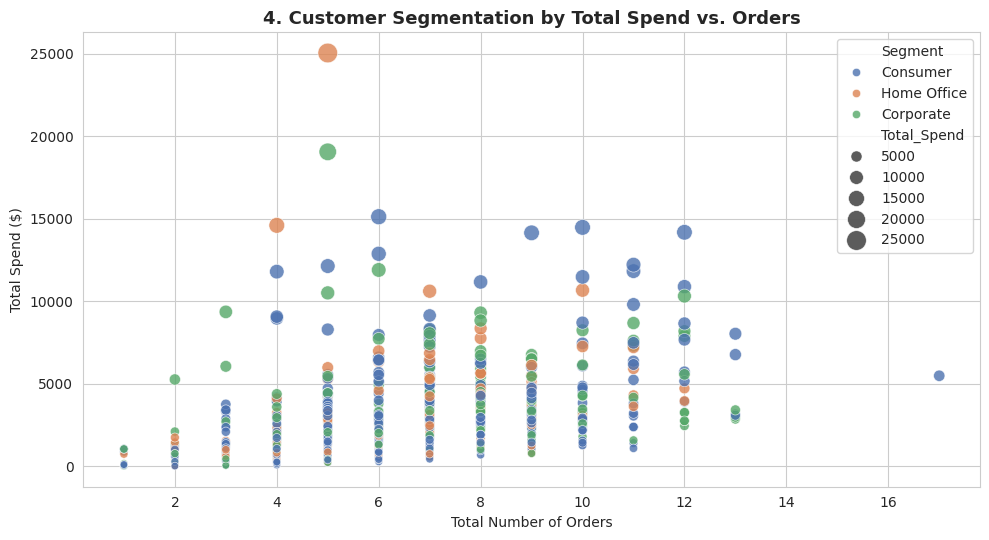

In [9]:
# Visual 4: Customer Segmentation Scatter Plot
cust_spend = df.groupby(['Customer ID', 'Segment']).agg(
    Total_Orders=('Order ID', 'nunique'),
    Total_Spend=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()

plt.figure(figsize=(10, 5.5))
sns.scatterplot(
    data=cust_spend, x='Total_Orders', y='Total_Spend',
    hue='Segment', size='Total_Spend', sizes=(30, 200), alpha=0.8, palette='deep'
)
plt.title('4. Customer Segmentation by Total Spend vs. Orders', fontsize=13, fontweight='bold')
plt.xlabel('Total Number of Orders')
plt.ylabel('Total Spend ($)')
plt.tight_layout()
plt.savefig('4_customer_spend_scatter_plot.png', dpi=300)
plt.show()

In [10]:
# Zip and download all project files
files_to_zip = [
    'superstore_cleaned.csv',
    '3_top_10_products_table.csv',
    '1_sales_trends_line_chart.png',
    '2_category_distribution_bar_chart.png',
    '4_customer_spend_scatter_plot.png'
]
with zipfile.ZipFile('Project_1_Submission_Files.zip', 'w') as zf:
    for f in files_to_zip:
        zf.write(f)

files.download('Project_1_Submission_Files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **💻 Step 5: Interactive Dashboard (Plotly.js)**
Generating a standalone, filterable HTML dashboard with dropdowns for Year, Region, and Product Category.

In [17]:
import json
from IPython.display import HTML, display
from google.colab import files

# 1. Prepare lightweight records for interactive filtering
records = df[[
    'Order ID', 'Order Year', 'Year-Month', 'Region', 'Category',
    'Sub-Category', 'Product Name', 'Customer ID', 'Segment', 'Sales', 'Profit'
]].rename(columns={
    'Order ID': 'oid', 'Order Year': 'yr', 'Year-Month': 'ym',
    'Region': 'reg', 'Category': 'cat', 'Sub-Category': 'sub',
    'Product Name': 'prod', 'Customer ID': 'cid', 'Segment': 'seg',
    'Sales': 's', 'Profit': 'p'
}).to_dict(orient='records')

years = sorted(df['Order Year'].unique().tolist())
regions = sorted(df['Region'].unique().tolist())
categories = sorted(df['Category'].unique().tolist())

year_options = ''.join([f'<option value="{y}">{y}</option>' for y in years])
region_options = ''.join([f'<option value="{r}">{r}</option>' for r in regions])
category_options = ''.join([f'<option value="{c}">{c}</option>' for c in categories])
records_json = json.dumps(records)

# 2. Build HTML/CSS/JS Dashboard Template (using plain string replacement to avoid brace errors)
html_template = """<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <title>Superstore Retail Analytics & Margin Optimization Hub</title>
  <script src="https://cdn.plot.ly/plotly-2.27.0.min.js"></script>
  <style>
    :root { --bg: #f4f6f9; --card: #ffffff; --accent: #2563eb; --text: #1e293b; --muted: #64748b; }
    * { box-sizing: border-box; font-family: 'Segoe UI', system-ui, sans-serif; }
    body { margin: 0; padding: 20px; background: var(--bg); color: var(--text); }
    .header {
      background: linear-gradient(135deg, #0f172a, #1e3a8a); color: white; padding: 18px 24px;
      border-radius: 12px; display: flex; justify-content: space-between; align-items: center;
      flex-wrap: wrap; gap: 16px; margin-bottom: 18px; box-shadow: 0 4px 12px rgba(0,0,0,0.08);
    }
    .header h1 { margin: 0; font-size: 20px; font-weight: 700; }
    .header p { margin: 4px 0 0; font-size: 13px; color: #cbd5e1; }
    .filters { display: flex; gap: 12px; flex-wrap: wrap; align-items: center; }
    .filter-group { display: flex; flex-direction: column; gap: 4px; }
    .filter-group label { font-size: 11px; text-transform: uppercase; color: #cbd5e1; }
    select, button {
      padding: 8px 12px; border-radius: 6px; border: 1px solid #475569;
      background: #1e293b; color: white; font-size: 13px; cursor: pointer;
    }
    button { background: #2563eb; border-color: #3b82f6; font-weight: 600; margin-top: 18px; }
    .kpi-grid { display: grid; grid-template-columns: repeat(auto-fit, minmax(190px, 1fr)); gap: 14px; margin-bottom: 18px; }
    .kpi-card { background: var(--card); padding: 16px 20px; border-radius: 10px; box-shadow: 0 2px 6px rgba(0,0,0,0.04); border-left: 4px solid var(--accent); }
    .kpi-title { font-size: 12px; color: var(--muted); text-transform: uppercase; font-weight: 600; }
    .kpi-value { font-size: 24px; font-weight: 700; margin-top: 6px; }
    .kpi-sub { font-size: 12px; color: var(--muted); margin-top: 4px; }
    .chart-grid { display: grid; grid-template-columns: repeat(2, 1fr); gap: 16px; }
    .chart-card { background: var(--card); border-radius: 10px; padding: 14px; box-shadow: 0 2px 6px rgba(0,0,0,0.04); min-height: 360px; }
    @media (max-width: 900px) { .chart-grid { grid-template-columns: 1fr; } }
  </style>
</head>
<body>
  <div class="header">
    <div>
      <h1>Superstore Retail Analytics &amp; Margin Optimization Hub</h1>
      <p>Project 1 Final Deliverable &bull; Filter by Year, Region &amp; Category</p>
    </div>
    <div class="filters">
      <div class="filter-group">
        <label>Time Period (Year)</label>
        <select id="yearFilter" onchange="updateDashboard()">
          <option value="ALL">All Years (2014-2017)</option>
          __YEAR_OPTIONS__
        </select>
      </div>
      <div class="filter-group">
        <label>Region</label>
        <select id="regionFilter" onchange="updateDashboard()">
          <option value="ALL">All Regions</option>
          __REGION_OPTIONS__
        </select>
      </div>
      <div class="filter-group">
        <label>Product Category</label>
        <select id="categoryFilter" onchange="updateDashboard()">
          <option value="ALL">All Categories</option>
          __CATEGORY_OPTIONS__
        </select>
      </div>
      <button onclick="resetFilters()">Reset Filters</button>
    </div>
  </div>
  <div class="kpi-grid">
    <div class="kpi-card"><div class="kpi-title">Total Sales</div><div class="kpi-value" id="kpiSales">$0</div><div class="kpi-sub" id="kpiAvgSales"></div></div>
    <div class="kpi-card" style="border-left-color:#10b981;"><div class="kpi-title">Total Profit</div><div class="kpi-value" id="kpiProfit">$0</div><div class="kpi-sub" id="kpiMargin"></div></div>
    <div class="kpi-card" style="border-left-color:#8b5cf6;"><div class="kpi-title">Total Orders</div><div class="kpi-value" id="kpiOrders">0</div><div class="kpi-sub" id="kpiAOV"></div></div>
    <div class="kpi-card" style="border-left-color:#f59e0b;"><div class="kpi-title">Active Customers</div><div class="kpi-value" id="kpiCustomers">0</div><div class="kpi-sub" id="kpiSpendPerCust"></div></div>
  </div>
  <div class="chart-grid">
    <div class="chart-card" id="lineChart"></div>
    <div class="chart-card" id="barChart"></div>
    <div class="chart-card" id="topProductsChart"></div>
    <div class="chart-card" id="scatterChart"></div>
  </div>
<script>
const rawData = __RECORDS_JSON__;
function fmtCurrency(v) { return '$' + v.toLocaleString('en-US', {minimumFractionDigits:2, maximumFractionDigits:2}); }
function resetFilters() {
  document.getElementById('yearFilter').value = 'ALL';
  document.getElementById('regionFilter').value = 'ALL';
  document.getElementById('categoryFilter').value = 'ALL';
  updateDashboard();
}
function updateDashboard() {
  const yr = document.getElementById('yearFilter').value;
  const reg = document.getElementById('regionFilter').value;
  const cat = document.getElementById('categoryFilter').value;
  const filtered = rawData.filter(d => (yr==='ALL'||String(d.yr)===yr) && (reg==='ALL'||d.reg===reg) && (cat==='ALL'||d.cat===cat));
  let totalSales = 0, totalProfit = 0;
  const orderSet = new Set(), custSet = new Set();
  filtered.forEach(d => { totalSales += d.s; totalProfit += d.p; orderSet.add(d.oid); custSet.add(d.cid); });
  const totalOrders = orderSet.size, totalCust = custSet.size;
  document.getElementById('kpiSales').innerText = fmtCurrency(totalSales);
  document.getElementById('kpiAvgSales').innerText = 'Avg Line Sale: ' + fmtCurrency(filtered.length ? totalSales/filtered.length : 0);
  document.getElementById('kpiProfit').innerText = fmtCurrency(totalProfit);
  document.getElementById('kpiMargin').innerText = 'Profit Margin: ' + (totalSales ? (totalProfit/totalSales*100).toFixed(2) : '0.00') + '%';
  document.getElementById('kpiOrders').innerText = totalOrders.toLocaleString();
  document.getElementById('kpiAOV').innerText = 'Avg Order Value: ' + fmtCurrency(totalOrders ? totalSales/totalOrders : 0);
  document.getElementById('kpiCustomers').innerText = totalCust.toLocaleString();
  document.getElementById('kpiSpendPerCust').innerText = 'Avg Spend/Customer: ' + fmtCurrency(totalCust ? totalSales/totalCust : 0);

  const monthlyMap = {};
  filtered.forEach(d => { monthlyMap[d.ym] = (monthlyMap[d.ym] || 0) + d.s; });
  const months = Object.keys(monthlyMap).sort();
  Plotly.react('lineChart', [{ x: months, y: months.map(m => monthlyMap[m]), type: 'scatter', mode: 'lines+markers', line: {color:'#2563eb', width:2.5} }],
    { title: {text:'<b>1. Sales Trends Over Time (Monthly)</b>', font:{size:14}}, margin:{t:45,l:55,r:20,b:50}, yaxis:{tickprefix:'$'}, height:340 }, {responsive:true});

  const subMap = {};
  filtered.forEach(d => { if(!subMap[d.sub]) subMap[d.sub]={s:0,p:0}; subMap[d.sub].s+=d.s; subMap[d.sub].p+=d.p; });
  const subs = Object.keys(subMap).sort((a,b) => subMap[a].s - subMap[b].s);
  Plotly.react('barChart', [
    { y: subs, x: subs.map(k=>subMap[k].s), name:'Sales', type:'bar', orientation:'h', marker:{color:'#1e3a8a'} },
    { y: subs, x: subs.map(k=>subMap[k].p), name:'Profit', type:'bar', orientation:'h', marker:{color:'#10b981'} }
  ], { title:{text:'<b>2. Sales & Profit Across Product Sub-Categories</b>', font:{size:14}}, barmode:'group', margin:{t:45,l:105,r:20,b:45}, xaxis:{tickprefix:'$'}, legend:{orientation:'h',y:1.12}, height:340 }, {responsive:true});

  const prodMap = {};
  filtered.forEach(d => { prodMap[d.prod] = (prodMap[d.prod] || 0) + d.s; });
  const topProds = Object.entries(prodMap).sort((a,b)=>b[1]-a[1]).slice(0,10).reverse();
  Plotly.react('topProductsChart', [{
    y: topProds.map(x => x[0].length>28 ? x[0].slice(0,28)+'...' : x[0]), x: topProds.map(x=>x[1]),
    text: topProds.map(x=>fmtCurrency(x[1])), textposition:'auto', type:'bar', orientation:'h', marker:{color:'#3b82f6'}
  }], { title:{text:'<b>3. Top 10 Performing Products by Revenue</b>', font:{size:14}}, margin:{t:45,l:185,r:20,b:45}, xaxis:{tickprefix:'$'}, height:340 }, {responsive:true});

  const custMap = {};
  filtered.forEach(d => { if(!custMap[d.cid]) custMap[d.cid]={orders:new Set(),spend:0,profit:0,seg:d.seg}; custMap[d.cid].orders.add(d.oid); custMap[d.cid].spend+=d.s; custMap[d.cid].profit+=d.p; });
  const segColors = {'Consumer':'#2563eb', 'Corporate':'#10b981', 'Home Office':'#f59e0b'};
  const traces = ['Consumer','Corporate','Home Office'].map(seg => {
    const pts = Object.entries(custMap).filter(([_,v]) => v.seg===seg);
    return { x: pts.map(([_,v])=>v.orders.size), y: pts.map(([_,v])=>v.spend), mode:'markers', type:'scatter', name:seg, marker:{size:8,opacity:0.75,color:segColors[seg]} };
  });
  Plotly.react('scatterChart', traces, { title:{text:'<b>4. Customer Segmentation by Total Spend vs. Orders</b>', font:{size:14}}, margin:{t:45,l:60,r:20,b:45}, xaxis:{title:'Total Orders'}, yaxis:{tickprefix:'$'}, legend:{orientation:'h',y:1.12}, height:340 }, {responsive:true});
}
updateDashboard();
</script>
</body>
</html>"""

html_final = (
    html_template
    .replace('__YEAR_OPTIONS__', year_options)
    .replace('__REGION_OPTIONS__', region_options)
    .replace('__CATEGORY_OPTIONS__', category_options)
    .replace('__RECORDS_JSON__', records_json)
)

dashboard_filename = 'Superstore_Retail_Analytics_Dashboard.html'
with open(dashboard_filename, 'w', encoding='utf-8') as f:
    f.write(html_final)

print(f"Interactive HTML dashboard saved as: {dashboard_filename}")
display(HTML(html_final))
files.download(dashboard_filename)

Interactive HTML dashboard saved as: Superstore_Retail_Analytics_Dashboard.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# **💡 Key Business Insights & Strategic Recommendations**

1. **Regional Performance:** The **West Region** leads in total revenue (**\$725,457.82**) and profit (**\$108,418.45**, **14.94%** margin), while the **Central Region** lags with a **7.92%** profit margin due to aggressive furniture discounting.
2. **Category Profitability:** **Technology** is the most profitable category (**\$836,154.03** sales, **\$145,454.95** profit). Conversely, **Furniture** generates **\$741,718.42** in sales but only **\$18,463.33** in profit (**2.49%** margin) due to net losses in **Tables (-\$17,725)** and **Bookcases (-\$3,473)**.
3. **The Discount Cliff:** Orders with **0% discount** achieve a **29.51% margin**, while discounts of **30% or higher** result in a **90%+ loss-making rate**, draining **-\$135,376** in net profit.
4. **Seasonality:** Annual revenue grew **51.5%** from 2014 to 2017, with nearly **40% of annual sales** concentrated in **Q4 (November–December)**.

### 🎯 Recommendations:
* **Cap Discounts at 20%:** Enforce approval rules for discounts above 20% on Tables, Bookcases, and Binders.
* **Bundle Loss-Making Items:** Pair slow-moving Furniture items with high-margin Office Supplies.
* **Pre-Stock Q4 Inventory:** Scale Technology inventory in the West/East regions ahead of the Q4 holiday surge.